# 09 - Detection avec YOLOX (Megvii, Apache-2.0) : boucle d'entrainement ecrite, decodage en numpy

YOLOX est un YOLO sans ancres, proche d'YOLO11 en precision, sous licence Apache-2.0 (utilisable
dans un produit ferme, contrairement a Ultralytics en AGPL). La librairie fournit le reseau, la
perte (SimOTA) et les augmentations ; tout le reste est ecrit ici :

- le pretraitement YOLOX, qui differe d'Ultralytics sur trois points (le piege classique) ;
- le chargement des poids COCO (tete de classification reinitialisee) ;
- la boucle : SGD Nesterov a trois groupes, montee quadratique puis cosinus, moyenne mobile des
  poids (EMA), mAP de validation a chaque epoque, arret anticipe ;
- l'export ONNX et le decodage des grilles + NMS en numpy, verifies contre PyTorch.

Prerequis : `pip install --no-build-isolation --no-deps yolox==0.3.0` + extra `yolox`,
`python tools/get_data/get_neu_det.py`, poids `weights/yolox_tiny.pth` (`tools/fetch_weights.py`).
Duree en mode QUICK sur 2 coeurs : environ 1 minute (davantage si la machine est chargee).

**Le fil** (memes etapes que le cours et que `ETAPES.md`, a la racine de la toolbox) :

```
1 Imports et reglages -> 2 Importer -> 3 Cataloguer -> 4 Decouper -> 5 Pretraiter
  -> 6 Augmenter -> 7 Charger par lots -> 8 Modele -> 9 Perte et optimiseur -> 10 Entrainer
  -> 13 Predire -> 11 Evaluer -> 12 Sauvegarder et exporter -> 13 Predire (decodage en numpy)
```

La prediction (13) vient avant l'evaluation (11) : on evalue le chemin de production.

## Etape 1 - Imports et reglages

Deux cellules : d'abord REGLAGES (tout ce qu'on change pour ses propres donnees est la, et
seulement la), puis les imports et la preparation (affichage, graine du hasard).

In [1]:
# REGLAGES : tout ce qu'on change pour ses propres donnees est ici.
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import torch  # PyTorch : calcul sur des tenseurs (tableaux de nombres, sur CPU ou GPU) et reseaux de neurones

QUICK = True  # True : essai court sur CPU (240 images, 2 epoques = 2 passages sur les images) ; False : complet (GPU conseille)

IMAGES_DIR = Path("data/raw/neu_det/IMAGES")  # dossier des images NEU-DET (photos de defauts de surface sur de l'acier, 6 classes)
# un XML Pascal VOC par image, de meme nom : il decrit les boites (rectangles) des defauts
ANNOTATIONS_DIR = Path("data/raw/neu_det/ANNOTATIONS")
COLOR = "gray"  # lecture en niveaux de gris (acier sans couleur) ; "rgb" pour des images en couleur
PREPROCESS = []  # pretraitements avant le reseau ([] = aucun) ; ex. [{"name": "clahe", "clip_limit": 2.0, "tile_grid": 8}]
MAX_IMAGES = 240 if QUICK else None  # mode QUICK : 240 images seulement pour aller vite ; None = toutes les images
VAL_FRACTION, TEST_FRACTION = 0.15, 0.15  # part des images pour la validation (reglages) et pour le test final (note de fin) : 15 % chacune
SEED = 42  # graine du hasard (= runtime.seed de la toolbox) : meme decoupage et meme entrainement que la recette

VARIANT = "tiny"  # taille du modele YOLOX : nano | tiny | s | m | l (plus grand = plus precis mais plus lent)
# poids officiels pre-entraines sur COCO (grand jeu public, 80 classes), release GitHub 0.1.1rc0
WEIGHTS = Path(f"weights/yolox_{VARIANT}.pth")
INPUT_SIZE = 320  # cote en pixels de l'image carree donnee au reseau (multiple de 32)
EPOCHS = 2 if QUICK else 40  # nombre d'epoques : passages complets sur les images d'entrainement
BATCH_SIZE = 8 if QUICK else 16  # lot (batch) : images traitees ensemble a chaque pas ; plus grand = plus rapide mais plus de memoire
BASIC_LR_PER_IMG = 1.5625e-4  # taux d'apprentissage (taille des corrections) par image : 0.01 pour un lot de 64, valeur officielle
WARMUP_EPOCHS = 1 if QUICK else 2  # echauffement (warmup) : epoques ou le taux d'apprentissage monte doucement depuis presque 0
MIN_LR_RATIO = 0.05  # a la fin, le taux d'apprentissage descend jusqu'a 5 % de sa valeur de depart
WEIGHT_DECAY = 5e-4  # decroissance des poids : petite penalite qui garde les poids petits (limite le surapprentissage)
EMA = True  # EMA : moyenne mobile des poids, plus stable que les poids bruts ; c'est elle qu'on evalue et sauvegarde
FLIP_PROB, HSV_PROB = 0.5, 1.0  # augmentations : retournement horizontal 1 fois sur 2, couleurs (HSV) modifiees a chaque image
MAX_LABELS = 50  # au plus 50 boites par image : toutes les cibles d'un lot doivent avoir la meme forme
PATIENCE = 2 if QUICK else 8  # arret anticipe : on stoppe apres ce nombre d'epoques sans progres en validation

# score mini : 0.001 pour la mAP (note globale), 0.25 en usage ; NMS : retire les doublons dont l'IoU (recouvrement) depasse 0.6
CONF_EVAL, CONF_PREDICT, IOU_NMS = 0.001, 0.25, 0.6
VERIFY_CONF = 0.05  # seuil de score utilise pour comparer ONNX et PyTorch apres l'export
OPSET = 18  # version des operations ONNX (format standard de modele, executable sans PyTorch)

# calcul sur la carte graphique (GPU) si elle existe, sinon sur le processeur (CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path("outputs/notebooks/09_detection_yolox")  # dossier ou ce notebook ecrit ses resultats (poids, ONNX, carte du modele)
# decoupage ecrit par la recette (script de production) : sert a verifier qu'on utilise les memes images
RECIPE_SPLIT = Path("outputs/detection/quick_split.csv" if QUICK else "outputs/detection/neu_det_split.csv")
OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier de sortie (et ses parents) s'il n'existe pas encore
print("appareil :", DEVICE, "| mode", "QUICK" if QUICK else "complet")  # affiche ou tourne le calcul et le mode choisi

appareil : cpu | mode QUICK


In [2]:
import contextlib  # contextlib : outils pour les blocs "with" (ici, faire taire les affichages de pycocotools)
import io  # io : flux en memoire ; StringIO = un "faux fichier" texte qui avale ce qu'on veut cacher
import json  # json : lire et ecrire du texte JSON (metriques, carte du modele)
import math  # math : fonctions mathematiques de base (cosinus, pi)
import platform  # platform : infos sur la machine (version de Python notee dans la carte)
import random  # random : tirages au hasard de Python (sa graine est fixee plus bas)
import time  # time : chronometre pour mesurer les durees
import warnings  # warnings : masquer des avertissements connus et sans danger
import xml.etree.ElementTree as ET  # ElementTree : lire les fichiers XML d'annotations
from collections import Counter  # Counter : compte les occurrences (classe la plus frequente d'une image)
from datetime import UTC, datetime  # datetime : date et heure ; UTC = heure universelle, la meme partout

import cv2  # OpenCV : lecture, ecriture et traitement d'images
import matplotlib.pyplot as plt  # matplotlib : tracer des courbes et afficher des images
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import pandas as pd  # pandas : tableaux de donnees (DataFrame), ici le catalogue des images
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from sklearn.model_selection import train_test_split  # train_test_split : coupe une liste en deux parties tirees au hasard
from torch import nn  # nn : briques des reseaux de neurones (couches, activations)
from torch.utils.data import DataLoader, Dataset  # Dataset : sait lire UN exemple ; DataLoader : les regroupe en lots

from vtb import viz  # viz : affichage de la toolbox (grilles d'images, courbes en direct, tableaux)

viz.setup_notebook(dpi=80, fmt="jpeg")  # reglage des figures : resolution moderee et format jpeg (notebook plus leger)
# yolox utilise une ecriture d'autocast obsolete : avertissement sans effet sur CPU, on le masque
warnings.filterwarnings("ignore", category=FutureWarning)
random.seed(SEED)  # fixe le hasard de Python : memes tirages a chaque execution
np.random.seed(SEED)  # fixe le hasard de numpy (utilise par les augmentations de YOLOX)
_ = torch.manual_seed(SEED)  # fixe le hasard de PyTorch (poids de depart, melange des lots) ; "_ =" ignore la valeur renvoyee

## Etapes 2 a 4 - Importer, cataloguer, decouper : annotations et decoupage (comme le notebook 08)

Lecture des XML Pascal VOC, decoupage PAR IMAGE stratifie sur la classe principale, avec
l'algorithme de `vtb.split` : les quatre moteurs (notebooks 08 a 11) voient les memes images.
Explications detaillees et regard sur les donnees : notebook 08, etapes 2 a 4.

In [3]:
# extensions de fichier acceptees comme images (comparees en minuscules)
IMAGE_EXTENSIONS = {".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff"}


def read_image(path, color="gray"):  # lit une image et la renvoie en gris (H, W) ou en couleur RGB (H, W, 3)
    """Fichier -> (H, W) en gris ou (H, W, 3) RGB ; robuste aux chemins Windows (octets puis decodage)."""
    # octets bruts du fichier puis decodage tel quel (marche aussi avec des accents dans le chemin)
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_UNCHANGED)
    if image is None:  # None = le fichier n'est pas une image lisible
        raise ValueError(f"image illisible : {path}")  # on arrete tout de suite avec un message clair
    if image.ndim == 3 and image.shape[2] == 4:  # image a 4 canaux : couleur + transparence (alpha)
        image = image[:, :, :3]  # on garde les 3 canaux de couleur, on jette la transparence
    if color == "gray":  # si on veut du gris
        # image couleur -> gris ; image deja grise : rendue telle quelle
        return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image
    # couleur : BGR (ordre d'OpenCV) -> RGB ; gris : canal recopie 3 fois
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if image.ndim == 3 else np.stack([image] * 3, axis=-1)


def to_three_channels(image):  # renvoie toujours une image a 3 canaux (le reseau attend 3 canaux)
    # deja 3 canaux : inchangee ; gris (2D) : on recopie le canal 3 fois
    return image if image.ndim == 3 else np.stack([image] * 3, axis=-1)


def read_voc(xml_path):  # lit un XML Pascal VOC ; renvoie largeur, hauteur, boites (n, 4) et noms de classes
    root = ET.parse(xml_path).getroot()  # ouvre le XML et prend sa balise racine <annotation>
    # taille de l'image notee dans le XML (float puis int : accepte "200.0")
    width, height = int(float(root.findtext("size/width"))), int(float(root.findtext("size/height")))
    boxes, labels = [], []  # listes a remplir : une boite et un nom de classe par objet
    for obj in root.iter("object"):  # pour chaque objet annote dans l'image
        b = obj.find("bndbox")  # la balise qui contient la boite englobante (bounding box)
        # coins haut-gauche (x1, y1) et bas-droit (x2, y2), en pixels
        x1, y1, x2, y2 = (float(b.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))
        # boite ramenee a l'interieur de l'image si elle deborde
        boxes.append([max(0.0, x1), max(0.0, y1), min(float(width), x2), min(float(height), y2)])
        labels.append(obj.findtext("name").strip())  # nom de la classe, sans espaces autour
    # reshape(-1, 4) : tableau (0, 4) meme sans objet, pour garder la meme forme
    return width, height, np.array(boxes, np.float32).reshape(-1, 4), labels


def main_label(labels):  # classe la plus frequente de l'image (sert a equilibrer le decoupage)
    return Counter(labels).most_common(1)[0][0] if labels else "background"  # aucune boite : "background" (fond, image sans defaut)


def can_stratify(labels, fraction):  # dit si on peut stratifier (garder les memes proportions de classes dans chaque part)
    counts = labels.value_counts()  # nombre d'images par classe principale
    # 2 classes ou plus, 2 images mini par classe, et au moins une place par classe dans la part tiree
    return len(counts) > 1 and counts.min() >= 2 and fraction * len(labels) >= len(counts)


def holdout(index, labels, fraction, seed):  # tire au hasard une part `fraction` des images ; renvoie leurs index
    # stratifie si possible ; "_" = la part gardee (inutile ici), "held" = la part mise de cote
    _, held = train_test_split(index, test_size=fraction, stratify=labels if can_stratify(labels, fraction) else None, random_state=seed)
    return pd.Index(held)  # index pandas des images mises de cote


records = []  # une fiche par image : chemin, taille, boites, classes
# chaque fichier image du dossier (sous-dossiers compris), trie par nom
for image_path in sorted(p for p in IMAGES_DIR.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS):
    # son XML porte le meme nom (stem = nom sans extension)
    width, height, boxes, labels = read_voc(ANNOTATIONS_DIR / f"{image_path.stem}.xml")
    # range la fiche de l'image
    records.append({"path": str(image_path), "width": width, "height": height, "boxes": boxes, "labels": labels})
# liste triee des classes presentes : leur position donne leur numero
CLASS_NAMES = sorted({label for r in records for label in r["labels"]})
CLASS_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}  # nom de classe -> numero (0, 1, 2...), ce que le reseau manipule
by_path = {r["path"]: r for r in records}  # chemin -> fiche, pour retrouver une fiche vite

# tableau : une ligne par image avec sa classe principale
catalog = pd.DataFrame([{"path": r["path"], "label": main_label(r["labels"])} for r in records])
if MAX_IMAGES is not None and len(catalog) > MAX_IMAGES:  # si on limite le nombre d'images (mode QUICK)
    # tire MAX_IMAGES images au hasard (random_state=0 : toujours les memes), remises dans l'ordre
    catalog = catalog.sample(n=MAX_IMAGES, random_state=0).sort_values("path").reset_index(drop=True)
labels = catalog["label"].astype(str)  # classe principale de chaque image, en texte
catalog["split"] = "train"  # par defaut, chaque image va dans l'entrainement
catalog.loc[holdout(catalog.index, labels, TEST_FRACTION, SEED), "split"] = "test"  # 15 % des images mises de cote pour le test
rest = catalog[catalog["split"] == "train"]  # les images restantes
# 15 % du total pris dans le reste pour la validation (0.15 / 0.85 du reste)
catalog.loc[holdout(rest.index, labels[rest.index], VAL_FRACTION / (1 - TEST_FRACTION), SEED), "split"] = "val"
catalog.to_csv(OUT / "split.csv", index=False)  # sauvegarde le decoupage pour le relire ou le comparer
SPLIT_MATCHES_RECIPE = None  # None = pas de decoupage de recette a comparer
if RECIPE_SPLIT.exists():  # si la recette a deja ecrit son decoupage
    # on le lit (keep_default_na=False : aucun texte lu comme valeur manquante)
    recipe = pd.read_csv(RECIPE_SPLIT, keep_default_na=False)[["path", "split"]]
    # jointure par chemin : True si chaque image est dans la meme part (train/val/test) que dans la recette
    SPLIT_MATCHES_RECIPE = bool(catalog[["path", "split"]].merge(recipe, on="path", suffixes=("", "_r")).eval("split == split_r").all())
print("decoupage identique a la recette :", SPLIT_MATCHES_RECIPE)  # True attendu (None si la recette n'a pas encore tourne)
# liste des fiches de chaque part : train, val, test
subsets = {s: [by_path[p] for p in catalog.loc[catalog["split"] == s, "path"]] for s in ("train", "val", "test")}
print({s: len(v) for s, v in subsets.items()}, CLASS_NAMES)  # nombre d'images par part et liste des classes

decoupage identique a la recette : True
{'train': 168, 'val': 36, 'test': 36} ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


## Etape 5 - Pretraiter : le pretraitement YOLOX, trois differences avec Ultralytics

1. l'image est redimensionnee sans deformer puis collee EN HAUT A GAUCHE d'un fond gris 114
   (Ultralytics la centre) ;
2. canaux en BGR (convention OpenCV) ;
3. valeurs laissees dans [0, 255] (pas de division par 255).

Donner a YOLOX une image preparee "a la Ultralytics" ne leve AUCUNE erreur : les detections
sont juste mauvaises. On ecrit la fonction a la main et on la compare a la fonction officielle
`yolox.data.data_augment.preproc`. Le ratio `r` sert a revenir en arriere : une boite du reseau
divisee par `r` est dans l'image pretraitee (pas de bordure a retirer : rien n'est decale).

ecart avec la fonction officielle : 0.0 | ratio 1.0666666666666667 1.0666666666666667


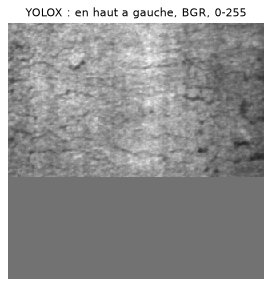

In [4]:
# TrainTransform : augmentations d'entrainement officielles ; preproc : pretraitement officiel
from yolox.data.data_augment import TrainTransform, preproc


def preprocess(image, steps=PREPROCESS):  # applique les pretraitements choisis (ex. CLAHE) ; renvoie l'image modifiee
    """Operations nommees (memes noms que vtb.preprocess) avant la mise a l'echelle du reseau."""
    for step in steps:  # pour chaque operation demandee, dans l'ordre
        params = {k: v for k, v in step.items() if k != "name"}  # ses parametres : tout sauf le nom
        if step["name"] == "clahe":  # CLAHE : egalisation de contraste par zones, fait ressortir les details fins
            grid = int(params.get("tile_grid", 8))  # l'image est decoupee en grid x grid tuiles (8 par defaut)
            # contraste limite par clip_limit pour ne pas amplifier le bruit
            image = cv2.createCLAHE(clipLimit=float(params.get("clip_limit", 2.0)), tileGridSize=(grid, grid)).apply(image)
        else:  # operation inconnue de ce notebook
            # on arrete avec un message clair
            raise ValueError(f"operation {step['name']} non ecrite dans ce notebook (catalogue : notebook 02)")
    return image  # image pretraitee, meme taille que l'entree


def yolox_input(image_bgr, size=INPUT_SIZE):  # prepare l'entree du reseau ; renvoie un tableau (3, S, S) et le ratio de reduction
    """BGR uint8 -> (3, S, S) float32 BGR [0, 255], image collee en haut a gauche ; rend aussi le ratio."""
    # facteur d'echelle qui fait tenir l'image dans le carre sans la deformer
    ratio = min(size / image_bgr.shape[0], size / image_bgr.shape[1])
    # nouvelle taille ; int() tronque, comme le code officiel
    new_w, new_h = int(image_bgr.shape[1] * ratio), int(image_bgr.shape[0] * ratio)
    canvas = np.full((size, size, 3), 114, dtype=np.uint8)  # fond carre gris (valeur 114), comme l'officiel
    # letterbox : image reduite sans deformation, collee en haut a gauche du fond gris
    canvas[:new_h, :new_w] = cv2.resize(image_bgr, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    # (H, W, C) -> (C, H, W) en float32 ; valeurs laissees en 0-255 ; contigu en memoire
    return np.ascontiguousarray(canvas.transpose(2, 0, 1), dtype=np.float32), ratio


def to_bgr3(image):  # renvoie une image BGR a 3 canaux (ordre de couleurs attendu par YOLOX)
    # gris : canal recopie 3 fois ; couleur : RGB -> BGR
    return np.stack([image] * 3, axis=-1) if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_RGB2BGR)


# premiere image d'entrainement : lue, pretraitee, mise en BGR
example = to_bgr3(preprocess(read_image(subsets["train"][0]["path"], COLOR)))
wide = cv2.resize(example, (300, 180))  # une image non carree (300 x 180) montre la difference
mine, ratio = yolox_input(wide)  # notre version du pretraitement
official, official_ratio = preproc(wide, (INPUT_SIZE, INPUT_SIZE))  # la version officielle de YOLOX, pour comparer
# ecart attendu : 0.0 (meme tableau, meme ratio)
print("ecart avec la fonction officielle :", float(np.abs(mine - official).max()), "| ratio", ratio, official_ratio)
# affiche l'entree du reseau (remise en uint8 et en (H, W, C) pour l'affichage)
viz.compare({"YOLOX : en haut a gauche, BGR, 0-255": mine.transpose(1, 2, 0).astype(np.uint8)}, bgr=True, size=3.5)
plt.show()  # dessine la figure

## Etapes 6 et 7 - Augmenter et charger par lots : le Dataset (image, cibles et echelles)

Chaque element rend `(image (3, S, S), cibles (MAX_LABELS, 5), echelle)` :

- cibles au format de la perte YOLOX : `classe, cx, cy, w, h` en pixels de l'ENTREE du reseau,
  completees par des zeros jusqu'a `MAX_LABELS` (toutes les images d'un lot ont la meme forme) ;
- a l'entrainement, `TrainTransform` (officiel) applique HSV aleatoire et retournement, puis le
  pretraitement ; les boites suivent ;
- `echelle = [r, sx, sy]` : `r` ramene de l'entree a l'image pretraitee, `sx, sy` de l'image
  pretraitee a l'image d'origine (1 sans redimensionnement). Deux reperes, deux facteurs :
  c'est la source classique de bugs de coordonnees.

In [5]:
class YoloxDataset(Dataset):  # jeu de donnees PyTorch : donne une image prete pour YOLOX, ses cibles et ses echelles
    def __init__(self, items, train_transform=None):  # items : fiches des images ; train_transform : augmentations (None hors entrainement)
        self.items, self.train_transform = items, train_transform  # on garde les fiches et les augmentations
        self.targets = [  # pour chaque image : tableau (n, 5) des boites suivies du numero de classe
            # colle les 4 coordonnees et le numero de classe ; reshape(-1, 5) garde la forme meme sans boite
            np.column_stack([r["boxes"], [CLASS_INDEX[x] for x in r["labels"]]]).astype(np.float32).reshape(-1, 5)
            for r in items  # une entree par image du jeu
        ]  # x1, y1, x2, y2, classe (format d'entree de TrainTransform)

    def __len__(self):  # nombre d'images du jeu (demande par le DataLoader)
        return len(self.items)  # une image par fiche

    def image(self, i):  # lit l'image numero i, la pretraite et la met en 3 canaux
        return to_three_channels(preprocess(read_image(self.items[i]["path"], COLOR)))  # lecture -> pretraitement -> 3 canaux

    def __getitem__(self, i):  # renvoie l'element i : image (3, S, S), cibles (MAX_LABELS, 5), echelle [r, sx, sy]
        record, image = self.items[i], self.image(i)  # la fiche et l'image pretraitee
        # facteurs image d'origine / image pretraitee (1 si meme taille)
        sx, sy = record["width"] / image.shape[1], record["height"] / image.shape[0]
        targets = self.targets[i].copy()  # copie : on ne modifie pas les cibles gardees en memoire
        targets[:, [0, 2]] /= sx  # x1, x2 : origine -> image pretraitee
        targets[:, [1, 3]] /= sy  # y1, y2 : meme chose en hauteur
        bgr = to_bgr3(image) if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_RGB2BGR)  # passage en BGR, l'ordre attendu par YOLOX
        if self.train_transform is not None:  # entrainement : augmentations aleatoires
            # augmente, pretraite, et rend les cibles (MAX_LABELS, 5) au format classe, cx, cy, w, h
            tensor, labels = self.train_transform(bgr, targets, (INPUT_SIZE, INPUT_SIZE))
            ratio = min(INPUT_SIZE / image.shape[0], INPUT_SIZE / image.shape[1])  # le meme ratio que celui applique par TrainTransform
        else:  # validation ou test : pas d'augmentation
            tensor, ratio = yolox_input(bgr)  # pretraitement seul
            labels = np.zeros((MAX_LABELS, 5), np.float32)  # cibles vides : l'evaluation compare aux boites des fiches
        scale = torch.tensor([ratio, sx, sy], dtype=torch.float32)  # les facteurs pour revenir a l'image d'origine
        # numpy -> tenseurs PyTorch (from_numpy partage la memoire, sans copie)
        return torch.from_numpy(np.ascontiguousarray(tensor, dtype=np.float32)), torch.from_numpy(labels), scale


# jeu d'entrainement, avec augmentations
train_set = YoloxDataset(subsets["train"], TrainTransform(max_labels=MAX_LABELS, flip_prob=FLIP_PROB, hsv_prob=HSV_PROB))
val_set, test_set = YoloxDataset(subsets["val"]), YoloxDataset(subsets["test"])  # validation et test, sans augmentation
x, y, scale = train_set[0]  # un element pour verifier les formes
print(  # affiche forme, type, plage de valeurs, nombre de cibles et echelle du premier element
    "image",  # etiquette
    tuple(x.shape),  # forme de l'image : (3, S, S)
    x.dtype,  # type des valeurs (float32)
    "valeurs",  # etiquette
    float(x.min()),  # plus petite valeur
    "-",  # separateur
    float(x.max()),  # plus grande valeur (255 au plus : pas de division par 255)
    "| cibles non vides :",  # etiquette
    int((y.sum(1) > 0).sum()),  # lignes de cibles non nulles = vraies boites
    "| echelle",  # etiquette
    scale.tolist(),  # [r, sx, sy]
)

image (3, 320, 320) torch.float32 valeurs 31.0 - 255.0 | cibles non vides : 3 | echelle [1.600000023841858, 1.0, 1.0]


## Etape 8 - Modele : CSPDarknet + PAFPN + tete decouplee sans ancres

Construit comme `yolox.exp.Exp.get_model` : profondeur et largeur selon la variante, reglages
officiels des BatchNorm, biais de la tete initialises pour une probabilite d'objet de ~1 %
(presque aucune cellule ne contient d'objet : partir de 50 % noierait la perte). Les poids
COCO sont repris pour tout ce qui a la meme forme : la tete de classification (80 classes)
ne correspond plus et repart de zero.

In [6]:
# briques YOLOX : PAFPN (extraction + melange des echelles), tete de detection, modele complet
from yolox.models import YOLOPAFPN, YOLOX, YOLOXHead

VARIANTS = {  # variante -> (facteur de profondeur, facteur de largeur, convolutions "depthwise" plus legeres)
    "nano": (0.33, 0.25, True),  # le plus petit : pour un CPU embarque
    "tiny": (0.33, 0.375, False),  # petit : bon compromis sur CPU
    "s": (0.33, 0.50, False),  # small
    "m": (0.67, 0.75, False),  # medium : plus de couches et de canaux
    "l": (1.0, 1.0, False),  # large : la taille de reference (facteurs 1)
}


def build_model(variant, num_classes):  # construit un YOLOX vierge pour num_classes classes ; renvoie le modele
    depth, width, depthwise = VARIANTS[variant]  # reglages de la variante choisie
    channels = [256, 512, 1024]  # canaux des trois niveaux d'echelle, avant multiplication par width
    model = YOLOX(  # le modele complet = squelette + tete
        # CSPDarknet (extrait les motifs) + PAFPN (melange les 3 echelles)
        YOLOPAFPN(depth, width, in_channels=channels, depthwise=depthwise),
        # tete decouplee : boite, objet et classe predits sur chaque cellule (case de la grille)
        YOLOXHead(num_classes, width, in_channels=channels, depthwise=depthwise),
    )
    for module in model.modules():  # pour chaque couche du modele
        if isinstance(module, nn.BatchNorm2d):  # BatchNorm : couche de normalisation (recentre et remet a l'echelle les valeurs)
            module.eps, module.momentum = 1e-3, 0.03  # reglages officiels de YOLOX pour ces couches
    model.head.initialize_biases(1e-2)  # biais de depart : ~1 % de probabilite d'objet par cellule
    return model  # modele pret a recevoir des poids


random.seed(SEED)  # meme etat aleatoire que la recette au moment de construire le modele (tirages de TrainTransform ensuite)
np.random.seed(SEED)  # idem pour numpy
_ = torch.manual_seed(SEED)  # idem pour PyTorch (poids de depart de la tete)
model = build_model(VARIANT, len(CLASS_NAMES))  # YOLOX vierge avec autant de classes que le jeu
if WEIGHTS.exists():  # si les poids COCO ont ete telecharges
    # charge le fichier ; ["model"] = dictionnaire nom -> tenseur
    state = torch.load(WEIGHTS, map_location="cpu", weights_only=False)["model"]
    own = model.state_dict()  # les tenseurs de notre modele (noms et formes)
    kept = {k: v for k, v in state.items() if k in own and own[k].shape == v.shape}  # on garde ceux qui ont le meme nom ET la meme forme
    model.load_state_dict(kept, strict=False)  # copie ces poids ; strict=False : les autres gardent leur valeur de depart
    print(  # bilan du chargement
        f"poids COCO : {len(kept)} / {len(own)} tenseurs repris ; ignores :",  # combien de tenseurs repris
        # les 3 premiers blocs ignores (la classification COCO a 80 classes)
        sorted({k.rsplit(".", 2)[0] for k in own if k not in kept})[:3],
        "...",  # la liste continue
    )
else:  # pas de fichier de poids
    print(f"{WEIGHTS} absent : depart de zero (tools/fetch_weights.py le telecharge)")  # previent : on entraine sans pre-entrainement
model.to(DEVICE)  # deplace le modele sur le GPU ou le CPU
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f} M parametres")  # taille du modele en millions de parametres (poids)

poids COCO : 456 / 462 tenseurs repris ; ignores : ['head.cls_preds'] ...
5.03 M parametres


## Etapes 9 et 10 - Perte et optimiseur, entrainer : la boucle d'entrainement

- **optimiseur** : SGD Nesterov, trois groupes ; les poids de BatchNorm et les biais sans
  decroissance des poids (les contraindre annulerait la normalisation) ;
- **taux** : `BASIC_LR_PER_IMG x taille du lot`, montee QUADRATIQUE pendant `WARMUP_EPOCHS`
  (la tete neuve donne de grands gradients) puis cosinus jusqu'a `MIN_LR_RATIO`, mis a jour a
  chaque ITERATION ;
- **perte** : calculee DANS le modele (`model(images, cibles)` rend un dict : boites (IoU),
  objet, classe) avec l'affectation SimOTA ;
- **EMA** : une moyenne mobile des poids, evaluee et sauvegardee a la place du modele brut
  (plus stable) ;
- **validation** : mAP COCO a chaque epoque ; on garde la meilleure, arret apres `PATIENCE`
  epoques sans progres.

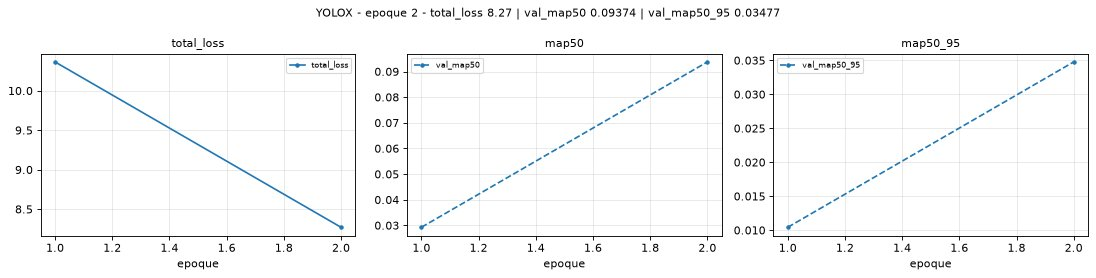

entrainement : 36.0 s ; meilleur mAP50-95 de validation 0.035


In [7]:
from pycocotools.coco import COCO  # pycocotools : calcul officiel de la mAP COCO ; COCO = la verite terrain
from pycocotools.cocoeval import COCOeval  # COCOeval : compare predictions et verite, calcule les precisions moyennes (AP)
from yolox.utils import ModelEMA, postprocess  # ModelEMA : moyenne mobile des poids ; postprocess : filtre par score + NMS


def coco_metrics(items, preds, class_names):  # renvoie mAP50, mAP50-95 et AP par classe
    """mAP@0.5, mAP@0.5:0.95 et AP par classe (pycocotools) ; verite et predictions en pixels d'origine."""
    index = {n: i for i, n in enumerate(class_names)}  # nom de classe -> numero
    images, annotations = [], []  # verite au format COCO : liste des images et liste des boites
    for image_id, record in enumerate(items):  # pour chaque image, avec son numero
        images.append({"id": image_id, "width": record["width"], "height": record["height"]})  # decrit l'image
        for (x1, y1, x2, y2), label in zip(record["boxes"], record["labels"]):  # pour chaque boite vraie de l'image
            w, h = float(x2 - x1), float(y2 - y1)  # largeur et hauteur de la boite
            annotations.append(  # ajoute la boite au format COCO
                {  # une boite = un dictionnaire de champs
                    "id": len(annotations) + 1,  # numero unique de la boite (COCO commence a 1)
                    "image_id": image_id,  # image a laquelle elle appartient
                    "category_id": index[label],  # numero de sa classe
                    "bbox": [float(x1), float(y1), w, h],  # format COCO : coin haut-gauche, largeur, hauteur
                    "area": w * h,  # aire (COCO s'en sert pour les tailles petit / moyen / grand)
                    "iscrowd": 0,  # 0 = objet isole (pas une foule groupee)
                }
            )
    results = [  # predictions au format COCO : une entree par boite predite
        {  # une prediction
            "image_id": i,  # image concernee
            "category_id": int(r[5]),  # classe predite
            "bbox": [float(r[0]), float(r[1]), float(r[2] - r[0]), float(r[3] - r[1])],  # x, y, largeur, hauteur
            "score": float(r[4]),  # score de confiance
        }
        for i, rows in enumerate(preds)  # pour chaque image et ses detections
        for r in rows  # pour chaque detection [x1 y1 x2 y2 score classe]
    ]
    if not results:  # aucune detection (modele encore nul)
        # tout a zero (pycocotools planterait sur une liste vide)
        return {"map50": 0.0, "map50_95": 0.0, "per_class": {n: {"ap50": 0.0, "ap50_95": 0.0} for n in class_names}}
    with contextlib.redirect_stdout(io.StringIO()):  # tout ce que pycocotools affiche part dans un faux fichier : sortie propre
        truth = COCO()  # objet verite terrain vide
        truth.dataset = {  # on le remplit a la main (au lieu de lire un fichier JSON)
            "images": images,  # les images
            "annotations": annotations,  # les boites vraies
            "categories": [{"id": i, "name": n} for i, n in enumerate(class_names)],  # les classes
        }
        truth.createIndex()  # construit les tables de recherche internes
        evaluator = COCOeval(truth, truth.loadRes(results), iouType="bbox")  # evaluation de boites (pas de masques)
        evaluator.evaluate()  # apparie predictions et verites, image par image et classe par classe
        evaluator.accumulate()  # construit les courbes precision-rappel
        evaluator.summarize()  # calcule les 12 chiffres resumes (evaluator.stats)
    # precision par (seuil IoU, rappel, classe) ; toutes tailles d'objets, 100 detections max
    precision = evaluator.eval["precision"][:, :, :, 0, -1]
    per_class = {}  # AP de chaque classe
    for k, class_id in enumerate(evaluator.params.catIds):  # pour chaque classe evaluee
        # -1 = pas de donnee : on l'ecarte ; at50 = seuil IoU 0.5 seul, valid = tous les seuils
        at50, valid = precision[0, :, k][precision[0, :, k] > -1], precision[:, :, k][precision[:, :, k] > -1]
        per_class[class_names[class_id]] = {  # AP de la classe
            "ap50": round(float(at50.mean()), 4) if at50.size else 0.0,  # AP a IoU 0.5 (boite juste si recouvrement >= 50 %)
            "ap50_95": round(float(valid.mean()), 4) if valid.size else 0.0,  # moyenne sur les seuils IoU 0.5 a 0.95 (plus exigeant)
        }
    # stats[0] = mAP50-95, stats[1] = mAP50
    return {"map50": float(evaluator.stats[1]), "map50_95": float(evaluator.stats[0]), "per_class": per_class}


def rows_of(result):  # convertit la sortie de postprocess en tableau (n, 6)
    """Sortie de yolox.utils.postprocess (x1 y1 x2 y2 objet proba classe) -> (n, 6) [x1 y1 x2 y2 score classe]."""
    if result is None:  # aucune boite pour cette image
        return np.zeros((0, 6), np.float32)  # tableau vide de 6 colonnes
    # tenseur -> numpy (detach : sans le suivi des gradients, ces derivees qui servent a corriger les poids)
    r = result.detach().cpu().numpy()
    # score final = objet x proba de classe ; colonnes x1 y1 x2 y2 score classe
    return np.column_stack([r[:, :4], r[:, 4] * r[:, 5], r[:, 6]]).astype(np.float32)


@torch.no_grad()  # pas de calcul de gradient ici : plus rapide, moins de memoire
def detect(net, dataset, conf, batch_size=BATCH_SIZE):  # predit tout un dataset ; renvoie une liste de tableaux (n, 6), un par image
    """Detections (n, 6) dans l'image d'ORIGINE pour tout un dataset (decodage et NMS de la librairie)."""
    net.eval()  # mode evaluation : BatchNorm figee, decodage des boites actif
    out = []  # detections de chaque image
    for images, _, scales in DataLoader(dataset, batch_size=batch_size, shuffle=False):  # par lots, dans l'ordre
        # reseau -> filtre par score + NMS (une sortie par image), associe a l'echelle [ratio, sx, sy]
        for result, (ratio, sx, sy) in zip(postprocess(net(images.to(DEVICE)), len(CLASS_NAMES), conf, IOU_NMS), scales.tolist()):
            rows = rows_of(result)  # (n, 6) en pixels de l'entree du reseau
            rows[:, [0, 2]] *= sx / ratio  # x : / ratio (entree -> image pretraitee) puis x sx (-> image d'origine)
            rows[:, [1, 3]] *= sy / ratio  # y : meme chose
            out.append(rows)  # range les detections de cette image
    return out  # une entree par image, dans l'ordre du dataset


def param_groups(net):  # range les poids en 3 groupes pour l'optimiseur ; renvoie (BatchNorm, poids, biais)
    bn, weights, biases = [], [], []  # trois listes vides
    for module in net.modules():  # pour chaque couche du reseau
        if hasattr(module, "bias") and isinstance(module.bias, nn.Parameter):  # si la couche a un biais apprenable
            biases.append(module.bias)  # groupe des biais (sans decroissance des poids)
        if isinstance(module, nn.BatchNorm2d):  # couche BatchNorm
            bn.append(module.weight)  # son poids : sans decroissance (le contraindre annulerait la normalisation)
        # autre couche avec un poids apprenable (convolution...)
        elif hasattr(module, "weight") and isinstance(module.weight, nn.Parameter):
            weights.append(module.weight)  # groupe avec decroissance des poids
    return bn, weights, biases  # les trois groupes


def warmup_cosine(iteration, total, warmup, min_ratio):  # coefficient du taux d'apprentissage a l'iteration donnee (entre 0 et 1)
    if warmup > 0 and iteration < warmup:  # pendant l'echauffement
        return max((iteration / warmup) ** 2, 1e-3)  # montee quadratique (au carre) depuis presque 0
    progress = (iteration - warmup) / max(1, total - warmup)  # avancement apres l'echauffement, de 0 a 1
    return min_ratio + 0.5 * (1 - min_ratio) * (1 + math.cos(math.pi * min(progress, 1.0)))  # descente en cosinus de 1 jusqu'a min_ratio


loader = DataLoader(  # distribue les images d'entrainement par lots
    train_set,  # jeu d'entrainement (avec augmentations)
    batch_size=BATCH_SIZE,  # images par lot
    shuffle=True,  # ordre melange a chaque epoque
    num_workers=0,  # lecture dans le processus principal (simple et reproductible)
    drop_last=len(train_set) > BATCH_SIZE,  # jette le dernier lot incomplet, sauf si tout tient en un seul lot
    generator=torch.Generator().manual_seed(SEED),  # melange reproductible (graine fixee)
)
bn, weights, biases = param_groups(model)  # les trois groupes de parametres
# optimiseur (corrige les poids) SGD, 1er groupe = BatchNorm ; momentum : garde l'elan des pas ; Nesterov : variante plus stable
optimizer = torch.optim.SGD(bn, lr=BASIC_LR_PER_IMG * BATCH_SIZE, momentum=0.9, nesterov=True)
optimizer.add_param_group({"params": weights, "weight_decay": WEIGHT_DECAY})  # 2e groupe : poids, avec decroissance
optimizer.add_param_group({"params": biases})  # 3e groupe : biais, sans decroissance (lr et momentum repris du 1er groupe)
total, warmup = EPOCHS * len(loader), round(WARMUP_EPOCHS * len(loader))  # iterations au total (une par lot) et iterations d'echauffement
# taux = taux de base x coefficient de warmup_cosine
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda it: warmup_cosine(it, total, warmup, MIN_LR_RATIO))
# copie dont les poids suivent lentement ceux du modele (moyenne mobile, poids 0.9998 a l'ancien)
ema = ModelEMA(model, 0.9998) if EMA else None
live = viz.LivePlot(metrics=("total_loss", "val_map50", "val_map50_95"), title="YOLOX")  # courbes mises a jour en direct a chaque epoque
best, bad, start = -1.0, 0, time.perf_counter()  # meilleure mAP vue (-1 : rien encore), epoques sans progres, heure de depart
for epoch in range(1, EPOCHS + 1):  # pour chaque epoque (numerotees a partir de 1)
    model.train()  # mode entrainement : BatchNorm apprend, le modele rend la perte
    sums = {}  # somme de chaque perte sur l'epoque
    for images, targets, _ in loader:  # pour chaque lot d'images et leurs cibles
        optimizer.zero_grad(set_to_none=True)  # efface les gradients du lot precedent
        # perte (erreur a reduire) calculee dans le modele : dict total_loss, iou_loss, conf_loss, cls_loss...
        losses = model(images.to(DEVICE), targets.to(DEVICE))
        losses["total_loss"].backward()  # calcule les gradients de la perte totale (retropropagation)
        optimizer.step()  # corrige les poids dans le sens qui reduit la perte
        scheduler.step()  # nouveau taux a chaque iteration (pas seulement a chaque epoque)
        if ema is not None:  # si la moyenne mobile est activee
            ema.update(model)  # elle avance d'un petit pas vers les poids actuels
        for k, v in losses.items():  # pour chaque perte du dictionnaire
            # ajoute sa valeur (item() : tenseur -> nombre Python)
            sums[k] = sums.get(k, 0.0) + (v.item() if torch.is_tensor(v) else float(v))
    evaluated = ema.ema if ema is not None else model  # on evalue la moyenne mobile si elle existe
    val = coco_metrics(subsets["val"], detect(evaluated, val_set, CONF_EVAL), CLASS_NAMES)  # mAP sur la validation
    if val["map50_95"] > best + 1e-4:  # vrai progres (plus de 0.0001)
        best, bad = val["map50_95"], 0  # nouveau record, compteur remis a zero
        # sauvegarde le meilleur modele
        torch.save({"model_state": evaluated.state_dict(), "epoch": epoch, "val_map50_95": best}, OUT / "best.pt")
    else:  # pas de progres
        bad += 1  # une epoque de plus sans progres
    # ajoute un point aux courbes (perte moyenne par lot, mAP de validation)
    live.update(epoch, total_loss=sums["total_loss"] / len(loader), val_map50=val["map50"], val_map50_95=val["map50_95"])
    if bad >= PATIENCE:  # trop d'epoques sans progres
        print(f"arret anticipe a l'epoque {epoch}")  # on le signale
        break  # on sort de la boucle des epoques
TRAIN_SECONDS = round(time.perf_counter() - start, 1)  # duree totale d'entrainement en secondes
live.close()  # fige les courbes
live.history.to_csv(OUT / "history.csv", index=False)  # sauvegarde l'historique des metriques
print(f"entrainement : {TRAIN_SECONDS} s ; meilleur mAP50-95 de validation {best:.3f}")  # bilan

## Etapes 11 et 13 - Evaluer et predire : predire par le chemin de production, evaluer, choisir le seuil

Le meilleur modele est recharge depuis `best.pt`. Prediction : lecture -> pretraitement ->
BGR -> `yolox_input` -> reseau (decodage des grilles dans le modele) -> filtre `objet x
classe >= conf` + NMS par classe (`yolox.utils.postprocess`, la reference) -> division par `r`
-> image d'origine. Puis mAP COCO, point de fonctionnement, seuil choisi sur la VALIDATION
(meilleur F1). Detail des metriques : notebook 08, etape 11.

test : mAP50 0.137 | mAP50-95 0.076 | 28.7 ms / image
seuil choisi sur la validation : 0.1 -> test {'tp': 11, 'fp': 55, 'fn': 73, 'precision': 0.1667, 'recall': 0.131, 'f1': 0.1467} | rappel image 0.4722
seuil de la recette 0.25 -> test {'tp': 7, 'fp': 9, 'fn': 77, 'precision': 0.4375, 'recall': 0.0833, 'f1': 0.14}


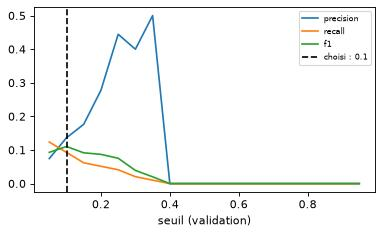

,ap50,ap50_95
crazing,0.0024,0.0005
inclusion,0.0278,0.0083
patches,0.3836,0.1501
pitted_surface,0.3562,0.2796
rolled-in_scale,0.0111,0.0056
scratches,0.0411,0.0121


In [8]:
model = build_model(VARIANT, len(CLASS_NAMES))  # modele vierge de meme architecture
# y charge les meilleurs poids sauvegardes (weights_only=True : lecture sure)
model.load_state_dict(torch.load(OUT / "best.pt", map_location="cpu", weights_only=True)["model_state"])
model = model.to(DEVICE).eval()  # sur l'appareil de calcul, en mode evaluation


@torch.no_grad()  # prediction seule : pas de gradients
def predict_images(net, images, conf):  # predit des images deja pretraitees ; renvoie un tableau (n, 6) par image
    """Images pretraitees -> (n, 6) dans le repere de ces images (chemin PyTorch de reference)."""
    prepared = [yolox_input(to_bgr3(im)) for im in images]  # (tableau, ratio) pour chaque image
    # empile en un lot (N, 3, S, S), en fait un tenseur sur l'appareil
    batch = torch.from_numpy(np.stack([t for t, _ in prepared])).to(DEVICE)
    out = []  # resultats par image
    for result, (_, ratio) in zip(postprocess(net(batch), len(CLASS_NAMES), conf, IOU_NMS), prepared):  # chaque image avec son ratio
        rows = rows_of(result)  # (n, 6) en pixels de l'entree
        rows[:, :4] /= ratio  # retour dans l'image pretraitee (rien a decaler : image collee en haut a gauche)
        out.append(rows)  # range
    return out  # une entree par image


def predict_paths(net, paths, conf, batch_size=16):  # predit des fichiers images ; renvoie les boites dans l'image d'origine
    out = []  # resultats par image
    for begin in range(0, len(paths), batch_size):  # par paquets de batch_size chemins
        originals = [read_image(p, COLOR) for p in paths[begin : begin + batch_size]]  # lit les images du paquet
        images = [preprocess(o) for o in originals]  # les pretraite
        for original, image, rows in zip(originals, images, predict_images(net, images, conf)):  # chaque image et ses detections
            rows[:, [0, 2]] *= original.shape[1] / image.shape[1]  # x : image pretraitee -> image d'origine
            rows[:, [1, 3]] *= original.shape[0] / image.shape[0]  # y : idem
            out.append(rows)  # range
    return out  # une entree par chemin, dans l'ordre


def box_iou(a, b):  # IoU de deux boites [x1, y1, x2, y2] : aire commune / aire de l'union, entre 0 et 1
    # aire de l'intersection (0 si les boites ne se touchent pas)
    inter = max(0.0, min(a[2], b[2]) - max(a[0], b[0])) * max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter  # aire A + aire B - partie commune
    return float(inter / union) if union > 0 else 0.0  # 0 si les boites sont degenerees (aire nulle)


# compte bonnes et mauvaises detections a un seuil ; renvoie precision, rappel, F1
def operating_point(items, preds, class_names, conf, iou=0.5):
    counts = {n: {"tp": 0, "fp": 0, "fn": 0} for n in class_names}  # par classe : vrais positifs, faux positifs, faux negatifs
    flagged = n_defect = 0  # images a defaut signalees par le modele / images a defaut
    for record, rows in zip(items, preds):  # pour chaque image et ses detections
        kept = rows[rows[:, 4] >= conf]  # detections au-dessus du seuil
        if len(record["labels"]):  # l'image contient au moins un defaut
            n_defect, flagged = n_defect + 1, flagged + bool(len(kept))  # compte l'image, et si le modele y a signale quelque chose
        for k, name in enumerate(class_names):  # classe par classe
            truth = [b for b, label in zip(record["boxes"], record["labels"]) if label == name]  # boites vraies de cette classe
            mine = kept[kept[:, 5] == k]  # boites predites de cette classe
            used = [False] * len(truth)  # chaque boite vraie ne peut etre trouvee qu'une fois
            for row in mine[np.argsort(-mine[:, 4])]:  # predictions de la plus sure a la moins sure
                # IoU avec chaque boite vraie encore libre (-1 si deja prise)
                scores = [box_iou(row[:4], t) if not used[j] else -1.0 for j, t in enumerate(truth)]
                best_j = int(np.argmax(scores)) if scores else -1  # la vraie qui recouvre le mieux (-1 s'il n'y en a pas)
                if best_j >= 0 and scores[best_j] >= iou:  # recouvrement suffisant : bonne detection
                    used[best_j] = True  # cette vraie est prise
                    counts[name]["tp"] += 1  # vrai positif
                else:  # rien de libre ou recouvrement trop faible
                    counts[name]["fp"] += 1  # faux positif (fausse alarme)
            counts[name]["fn"] += used.count(False)  # vraies jamais trouvees = faux negatifs (defauts rates)

    def rates(c):  # precision, rappel et F1 a partir des comptes
        p = c["tp"] / (c["tp"] + c["fp"]) if c["tp"] + c["fp"] else 0.0  # precision : part des detections qui sont justes
        r = c["tp"] / (c["tp"] + c["fn"]) if c["tp"] + c["fn"] else 0.0  # rappel : part des vrais defauts trouves
        # F1 : moyenne harmonique de la precision et du rappel
        return {**c, "precision": round(p, 4), "recall": round(r, 4), "f1": round(2 * p * r / (p + r), 4) if p + r else 0.0}

    total = {k: sum(c[k] for c in counts.values()) for k in ("tp", "fp", "fn")}  # comptes toutes classes confondues
    return {  # resultat
        "conf": conf,  # seuil utilise
        "overall": rates(total),  # toutes classes
        "per_class": {n: rates(c) for n, c in counts.items()},  # classe par classe
        # part des images a defaut ou le modele signale au moins une boite
        "image_recall": round(flagged / n_defect, 4) if n_defect else None,
    }


def choose_conf(items, preds, grid=None):  # choisit le seuil de score au meilleur F1 ; renvoie (seuil, tableau du balayage)
    grid = np.round(np.arange(0.05, 0.96, 0.05), 2) if grid is None else grid  # seuils essayes : 0.05, 0.10, ..., 0.95
    # une ligne par seuil : precision, rappel, F1...
    table = pd.DataFrame([{"conf": c, **operating_point(items, preds, CLASS_NAMES, c)["overall"]} for c in grid])
    # seuil du meilleur F1 (0.25 si F1 nul partout), et le tableau
    return (float(table.loc[table["f1"].idxmax(), "conf"]) if table["f1"].max() > 0 else CONF_PREDICT), table


# detections sur la validation (seuil tres bas : toutes les boites)
val_preds = predict_paths(model, [r["path"] for r in subsets["val"]], CONF_EVAL)
start = time.perf_counter()  # chrono
test_preds = predict_paths(model, [r["path"] for r in subsets["test"]], CONF_EVAL)  # detections sur le test
MS_PER_IMAGE = round(1000 * (time.perf_counter() - start) / len(test_preds), 1)  # temps moyen par image (lecture comprise), en ms
CHOSEN_CONF, sweep = choose_conf(subsets["val"], val_preds)  # seuil choisi sur la VALIDATION (le test reste neutre)
test_metrics = coco_metrics(subsets["test"], test_preds, CLASS_NAMES)  # mAP sur le test
op_chosen = operating_point(subsets["test"], test_preds, CLASS_NAMES, CHOSEN_CONF)  # precision / rappel au seuil choisi
op_recipe = operating_point(subsets["test"], test_preds, CLASS_NAMES, CONF_PREDICT)  # et au seuil de la recette (0.25)
# bilan sur le test
print(f"test : mAP50 {test_metrics['map50']:.3f} | mAP50-95 {test_metrics['map50_95']:.3f} | {MS_PER_IMAGE} ms / image")
# resultats au seuil choisi, et part des images a defaut signalees
print(f"seuil choisi sur la validation : {CHOSEN_CONF} -> test", op_chosen["overall"], "| rappel image", op_chosen["image_recall"])
print(f"seuil de la recette {CONF_PREDICT} -> test", op_recipe["overall"])  # resultats au seuil fixe de la recette
fig, ax = plt.subplots(figsize=(5.5, 3))  # une figure avec un seul graphique
for column in ("precision", "recall", "f1"):  # trois courbes
    ax.plot(sweep["conf"], sweep[column], label=column)  # metrique en fonction du seuil
ax.axvline(CHOSEN_CONF, color="k", linestyle="--", label=f"choisi : {CHOSEN_CONF}")  # trait vertical au seuil choisi
ax.set_xlabel("seuil (validation)")  # titre de l'axe horizontal
ax.legend(fontsize=7)  # legende
plt.show()  # affiche
display(pd.DataFrame(test_metrics["per_class"]).T)  # tableau des AP par classe (une ligne par classe)

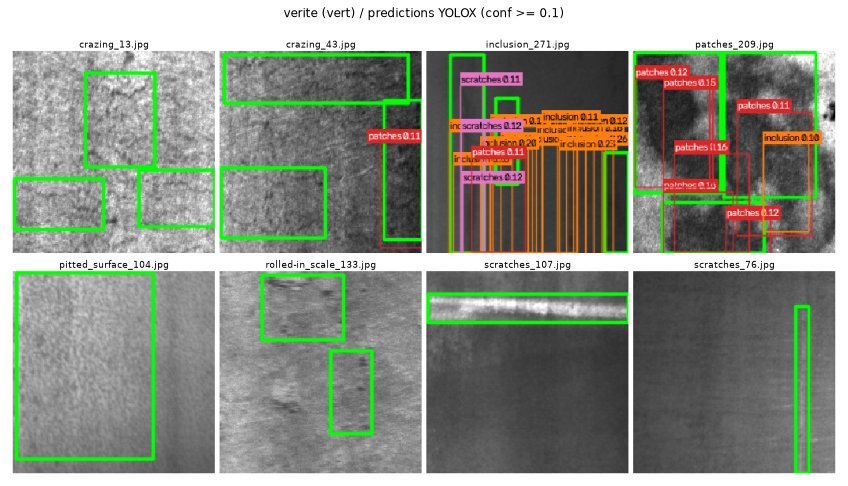

In [9]:
picked = [subsets["test"][i] for i in np.linspace(0, len(subsets["test"]) - 1, 8).astype(int)]  # 8 images de test reparties regulierement
pred_of = {r["path"]: p for r, p in zip(subsets["test"], test_preds)}  # chemin -> detections
viz.grid(  # grille d'images
    [  # une vignette dessinee par image choisie
        viz.draw_detections(  # dessine boites vraies et predites sur l'image
            read_image(r["path"], COLOR),  # image d'origine
            truth={"boxes": r["boxes"], "labels": [CLASS_INDEX[x] for x in r["labels"]]},  # verite terrain (boites et numeros de classe)
            # predictions : boites, classes et scores
            pred={"boxes": pred_of[r["path"]][:, :4], "labels": pred_of[r["path"]][:, 5].astype(int), "scores": pred_of[r["path"]][:, 4]},
            class_names=CLASS_NAMES,  # noms affiches
            conf=CHOSEN_CONF,  # seuil d'affichage
        )
        for r in picked  # pour chaque image choisie
    ],
    [Path(r["path"]).name for r in picked],  # titres : noms des fichiers
    ncols=4,  # 4 colonnes
    size=2.6,  # taille de chaque vignette
    suptitle=f"verite (vert) / predictions YOLOX (conf >= {CHOSEN_CONF})",  # titre general
)
plt.show()  # affiche

## Etapes 12 et 13 - Exporter et predire : exporter en ONNX et decoder en numpy

Procedure officielle : SiLU remplace par `x * sigmoid(x)` (exportable partout) et
`decode_in_inference = False` : l'ONNX sort les valeurs BRUTES `(A, 5 + C)` de chaque cellule
des trois grilles (pas 8, 16, 32). Le decodage, ecrit en numpy, est la fonction a porter en C# :

- `cx = (x + colonne) x pas`, `cy = (y + ligne) x pas`, `w = exp(w) x pas`, `h = exp(h) x pas` ;
- score = objet x probabilite de classe (deja passees par la sigmoide dans le graphe) ;
- filtre, coins, NMS par classe, division par le ratio.

Verifications : sorties brutes ONNX == PyTorch, puis boites ONNX + numpy == boites du chemin
PyTorch de reference (IoU moyen >= 0,98, sinon refus).

In [10]:
import onnx  # onnx : lire et ecrire le format ONNX
import onnxruntime as ort  # onnxruntime : moteur qui execute un modele ONNX sans PyTorch


class ExportSiLU(nn.Module):  # activation SiLU ecrite a la main, exportable partout
    def forward(self, x):  # calcul de la couche
        return x * torch.sigmoid(x)  # SiLU(x) = x * sigmoide(x) ; sigmoide : ramene une valeur entre 0 et 1


def replace_silu(module):  # remplace toutes les SiLU du reseau par ExportSiLU ; renvoie le module modifie
    for name, child in module.named_children():  # pour chaque sous-bloc direct
        if isinstance(child, nn.SiLU):  # c'est une SiLU
            setattr(module, name, ExportSiLU())  # on la remplace
        else:  # autre bloc
            replace_silu(child)  # on descend dedans (la fonction s'appelle elle-meme)
    return module  # le module modifie sur place


def yolox_decode(raw, size, strides=(8, 16, 32)):  # decode les grilles ; renvoie (A, 5 + C) avec cx, cy, w, h en pixels
    """Sortie brute (A, 5 + C) -> cx, cy, w, h en pixels de l'entree ; objet et classes inchanges."""
    grids, expanded = [], []  # position de chaque cellule, et pas de sa grille
    for stride in strides:  # pour chaque grille : une cellule couvre pas x pas pixels
        n = size // stride  # cellules par cote (320 / 8 = 40)
        rows_idx, cols_idx = np.meshgrid(np.arange(n), np.arange(n), indexing="ij")  # numero de ligne et de colonne de chaque cellule
        grids.append(np.stack((cols_idx, rows_idx), 2).reshape(-1, 2))  # liste (n*n, 2) des (colonne, ligne), ligne par ligne
        expanded.append(np.full((n * n, 1), stride))  # le pas, repete pour chaque cellule
    # les trois grilles mises bout a bout, en float32
    grid, stride = np.concatenate(grids).astype(np.float32), np.concatenate(expanded).astype(np.float32)
    out = raw.copy()  # copie : on garde la sortie brute intacte
    out[:, :2] = (out[:, :2] + grid) * stride  # centre : (decalage predit + position de la cellule) x pas
    out[:, 2:4] = np.exp(out[:, 2:4]) * stride  # taille : exponentielle (toujours positive) x pas
    return out  # cx, cy, w, h en pixels de l'entree ; objet et classes inchanges


def nms(boxes, scores, iou):  # NMS : supprime les boites en double ; renvoie les indices gardes
    order, keep = np.argsort(-scores), []  # indices du meilleur au moins bon score ; liste des gardes
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])  # aire de chaque boite
    while len(order):  # tant qu'il reste des boites a examiner
        i, rest = order[0], order[1:]  # la meilleure restante et les autres
        keep.append(i)  # on garde la meilleure
        # coin haut-gauche de chaque intersection
        xx1, yy1 = np.maximum(boxes[i, 0], boxes[rest, 0]), np.maximum(boxes[i, 1], boxes[rest, 1])
        xx2, yy2 = np.minimum(boxes[i, 2], boxes[rest, 2]), np.minimum(boxes[i, 3], boxes[rest, 3])  # coin bas-droit de chaque intersection
        inter = np.clip(xx2 - xx1, 0, None) * np.clip(yy2 - yy1, 0, None)  # aires des intersections (0 si pas de contact)
        # on ne garde que celles dont l'IoU avec la meilleure est <= iou
        order = rest[inter / (areas[i] + areas[rest] - inter + 1e-9) <= iou]
    return np.array(keep, dtype=np.int64)  # indices des boites gardees


def nms_per_class(rows, iou):  # NMS classe par classe ; renvoie les lignes gardees, triees par score
    # pour chaque classe presente : ses lignes, filtrees par la NMS
    kept = [rows[rows[:, 5] == c][nms(rows[rows[:, 5] == c, :4], rows[rows[:, 5] == c, 4], iou)] for c in np.unique(rows[:, 5])]
    out = np.concatenate(kept) if kept else np.zeros((0, 6), np.float32)  # tout rassemble (tableau vide s'il n'y a rien)
    return out[np.argsort(-out[:, 4])]  # du meilleur score au moins bon


def postprocess_yolox(raw, ratio, conf, iou, size=INPUT_SIZE):  # sortie ONNX brute d'une image -> detections (n, 6)
    """Sortie ONNX brute d'UNE image -> (n, 6) dans l'image pretraitee."""
    decoded = yolox_decode(raw, size)  # boites en pixels de l'entree
    probs = decoded[:, 5:]  # probabilites de chaque classe
    classes = probs.argmax(axis=1)  # classe la plus probable de chaque cellule
    scores = decoded[:, 4] * probs[np.arange(len(classes)), classes]  # score = objet x proba de cette classe
    keep = scores >= conf  # cellules au-dessus du seuil
    if not keep.any():  # aucune
        return np.zeros((0, 6), np.float32)  # tableau vide
    c = decoded[keep]  # les cellules gardees
    rows = np.column_stack(  # (n, 6) : x1, y1, x2, y2, score, classe
        # coins = centre -/+ moitie de la taille ; puis score et classe
        [c[:, 0] - c[:, 2] / 2, c[:, 1] - c[:, 3] / 2, c[:, 0] + c[:, 2] / 2, c[:, 1] + c[:, 3] / 2, scores[keep], classes[keep]]
    )
    rows = nms_per_class(rows.astype(np.float32), iou)  # suppression des doublons
    rows[:, :4] /= ratio  # retour dans l'image pretraitee
    return rows  # detections finales


def mean_best_iou(mine, reference):  # compare deux jeux de detections ; renvoie nombres de boites et IoU moyen
    ious = [  # pour chaque boite de "mine" : meilleur IoU avec une boite de la reference de la meme image
        max(1.0 if np.allclose(row[:4], r[:4], atol=0.5) else box_iou(row[:4], r[:4]) for r in ref)  # 1 si les coins sont a 0.5 px pres
        for rows, ref in zip(mine, reference)  # image par image
        for row in rows  # boite par boite
        if len(ref)  # seulement si la reference a des boites sur cette image
    ]
    return {  # bilan
        "boxes": int(sum(map(len, mine))),  # nombre de boites de notre chaine
        "reference_boxes": int(sum(map(len, reference))),  # nombre de boites de la reference
        "mean_iou": float(np.mean(ious)) if ious else None,  # IoU moyen (None si rien a comparer)
    }


net = replace_silu(model.cpu().eval())  # modele sur CPU, en evaluation, SiLU remplacees (modifie aussi "model" : meme objet)
DEVICE = torch.device("cpu")  # export et verification sur CPU
samples = [preprocess(read_image(r["path"], COLOR)) for r in subsets["val"][:4]]  # 4 images de validation pretraitees
reference = predict_images(net, samples, VERIFY_CONF)  # decodage PyTorch, avant de le retirer du graphe
net.head.decode_in_inference = False  # le reseau sort maintenant les valeurs brutes (decodage fait en numpy)
prepared = [yolox_input(to_bgr3(im)) for im in samples]  # entrees du reseau et ratios
batch = torch.from_numpy(np.stack([t for t, _ in prepared]))  # lot (4, 3, S, S)
onnx_path = OUT / "model.onnx"  # fichier ONNX a ecrire
with warnings.catch_warnings():  # les reglages d'avertissements reviennent a la normale a la fin du bloc
    warnings.simplefilter("ignore")  # exporteur TorchScript : avertissement d'obsolescence attendu
    torch.onnx.export(  # trace le reseau sur un exemple et ecrit le graphe ONNX
        net,  # le modele a exporter
        (batch[:1],),  # exemple d'entree (une image) qui sert a suivre les calculs
        str(onnx_path),  # fichier de sortie
        input_names=["images"],  # nom de l'entree dans le graphe
        output_names=["output"],  # nom de la sortie
        dynamic_axes={"images": {0: "batch"}, "output": {0: "batch"}},  # taille de lot libre (pas figee a 1)
        opset_version=OPSET,  # version des operations ONNX
        dynamo=False,  # exporteur classique par trace (TorchScript), pas le nouveau (dynamo)
    )
session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])  # charge l'ONNX dans onnxruntime, sur CPU
raw_onnx = session.run(None, {"images": batch.numpy()})[0]  # sorties brutes ONNX des 4 images
with torch.no_grad():  # sans gradients
    raw_torch = net(batch).numpy()  # sorties brutes PyTorch, pour comparer
# decodage numpy des sorties ONNX
mine = [postprocess_yolox(raw_onnx[i], ratio, VERIFY_CONF, IOU_NMS) for i, (_, ratio) in enumerate(prepared)]
EXPORT_CHECK = {  # resultats de la verification
    "raw_max_abs_diff": float(np.abs(raw_onnx - raw_torch).max()),  # plus grand ecart ONNX / PyTorch
    "raw_scale": float(np.abs(raw_torch).max()),  # ordre de grandeur des sorties (pour une tolerance relative)
    **mean_best_iou(mine, reference),  # boites et IoU moyen : chaine ONNX + numpy contre PyTorch
}
print(EXPORT_CHECK)  # affiche le bilan
# assert : arrete tout si c'est faux ; ecart tolere 1e-4 + 0.1 % de l'ordre de grandeur
assert EXPORT_CHECK["raw_max_abs_diff"] <= 1e-4 + 1e-3 * EXPORT_CHECK["raw_scale"], "sorties brutes ONNX differentes de PyTorch"
# IoU moyen >= 0.98 exige (None : aucune boite a comparer)
assert EXPORT_CHECK["mean_iou"] is None or EXPORT_CHECK["mean_iou"] >= 0.98, "le decodage numpy ne reproduit pas PyTorch"


def timed(fn, runs=20):  # temps moyen d'un appel de fn, en millisecondes
    for _ in range(3):  # 3 appels d'echauffement (non chronometres)
        fn()  # appel a vide
    begin = time.perf_counter()  # debut du chrono
    for _ in range(runs):  # appels chronometres
        fn()  # appel mesure
    return round(1000 * (time.perf_counter() - begin) / runs, 2)  # duree moyenne en ms


one = batch[:1]  # une seule image (lot de 1), le cas d'usage en production
with torch.no_grad():  # sans gradients
    # latence (temps d'une prediction) : PyTorch puis onnxruntime ; lambda = petite fonction sans nom
    LATENCY = {"torch_cpu_ms": timed(lambda: net(one)), "onnxruntime_cpu_ms": timed(lambda: session.run(None, {"images": one.numpy()}))}
print(LATENCY)  # temps par image : PyTorch contre onnxruntime

{'raw_max_abs_diff': 9.417533874511719e-06, 'raw_scale': 3.6859588623046875, 'boxes': 5, 'reference_boxes': 5, 'mean_iou': 1.0}


{'torch_cpu_ms': 53.74, 'onnxruntime_cpu_ms': 20.76}


## Etape 12 - Sauvegarder et exporter : la carte du modele

Les trois differences du pretraitement sont ecrites dans la carte : `color: BGR`, `scale: none`,
`resize: letterbox_top_left`. Le prefixe `yolox:` du nom choisit le decodeur en production.

In [11]:
card = {  # carte du modele : tout ce qu'il faut pour l'utiliser sans ce notebook
    "task": "detection",  # type de tache
    "model_name": f"yolox:yolox_{VARIANT}",  # le prefixe "yolox:" choisit le decodeur en production
    "created_utc": datetime.now(UTC).strftime("%Y-%m-%dT%H:%M:%SZ"),  # date de creation (heure universelle)
    "framework": {  # versions des outils, pour reproduire
        "python": platform.python_version(),  # version de Python
        "torch": torch.__version__,  # version de PyTorch
        "onnx": onnx.__version__,  # version d'onnx
        "onnxruntime": ort.__version__,  # version d'onnxruntime
    },
    "input": {  # comment preparer l'entree
        "name": "images",  # nom de l'entree du graphe
        "layout": "NCHW",  # ordre des axes : lot, canaux, hauteur, largeur
        "height": INPUT_SIZE,  # hauteur attendue
        "width": INPUT_SIZE,  # largeur attendue
        "channels": 3,  # 3 canaux
        "color": "BGR",  # difference 2 : ordre BGR
        "dtype": "float32",  # nombres a virgule sur 32 bits
        "scale": "none (values 0-255)",  # difference 3 : pas de division par 255
        "mean": [],  # pas de soustraction de moyenne
        "std": [],  # pas de division par un ecart-type
        "resize": "letterbox_top_left",  # difference 1 : image collee en haut a gauche
        "letterbox_pad_value": 114,  # gris du fond
        "dynamic_batch": True,  # taille de lot libre
        "read_color": COLOR,  # mode de lecture du fichier (gris ou couleur)
    },
    "preprocess": PREPROCESS,  # pretraitements a appliquer avant (ex. CLAHE)
    "outputs": [  # description des sorties
        {  # unique sortie
            "name": "output",  # son nom
            "shape": ["batch", "anchors", 5 + len(CLASS_NAMES)],  # (lot, cellules des 3 grilles, 4 coordonnees + objet + classes)
            "description": "sortie brute NON decodee (x, y, w, h, objet, classes)",  # rappel : le decodage reste a faire
        }
    ],
    "class_names": CLASS_NAMES,  # noms des classes, dans l'ordre des numeros
    "thresholds": {"conf": CHOSEN_CONF, "iou_nms": IOU_NMS},  # seuils a utiliser
    "postprocess": {  # comment decoder la sortie
        # etapes du decodage, dans l'ordre
        "steps": "decoder les grilles de pas 8/16/32 (cx = (x + col) * pas, w = exp(w) * pas) -> score = objet * proba -> filtre conf -> NMS par classe -> diviser par le ratio",
        # code de reference
        "reference": "notebooks/09_detection_yolox (postprocess_yolox) ; vtb.tasks.detection.yolox_backend.postprocess_onnx",
    },
    "metrics": {  # performances sur le test
        "map50": test_metrics["map50"],  # mAP a IoU 0.5
        "map50_95": test_metrics["map50_95"],  # mAP moyenne sur IoU 0.5 a 0.95
        "n_images": len(subsets["test"]),  # nombre d'images de test
        "operating_point": op_chosen["overall"],  # precision / rappel / F1 au seuil choisi
    },
    "latency_ms": LATENCY,  # temps par image
    "files": {"onnx": "model.onnx"},  # fichier du modele, dans le meme dossier
    "notes": f"notebook 09 ; verification ONNX : {EXPORT_CHECK}",  # trace de la verification d'export
}
(OUT / "model_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")  # ecrit la carte en JSON lisible (indent=2)
print(json.dumps(card["input"], indent=1))  # affiche la partie "entree"

{
 "name": "images",
 "layout": "NCHW",
 "height": 320,
 "width": 320,
 "channels": 3,
 "color": "BGR",
 "dtype": "float32",
 "scale": "none (values 0-255)",
 "mean": [],
 "std": [],
 "resize": "letterbox_top_left",
 "letterbox_pad_value": 114,
 "dynamic_batch": true,
 "read_color": "gray"
}


## Adapter a tes donnees

- Annotations : `IMAGES_DIR`, `ANNOTATIONS_DIR` (VOC) ; autre format : remplacer `read_voc`
  (notebook 04) en gardant `path, width, height, boxes, labels`.
- Variante : `VARIANT` (nano pour un CPU embarque, s ou m si la precision manque) ;
  `INPUT_SIZE` multiple de 32, proche de la taille utile des images.
- YOLOX n'apprend que des boites droites : un jeu en masques se convertit en boites englobantes.

## Resultats

In [12]:
recipe_file = Path("outputs/detection/quick_yolox/test_metrics.json")  # metriques ecrites par la recette quick_yolox
recipe = json.loads(recipe_file.read_text()) if QUICK and recipe_file.exists() else {}  # lues si disponibles (en mode QUICK seulement)
rows = {  # tableau de comparaison : une entree par source
    "notebook 09": {  # resultats de ce notebook
        "mAP50": test_metrics["map50"],  # mAP a IoU 0.5
        "mAP50-95": test_metrics["map50_95"],  # mAP sur IoU 0.5 a 0.95
        f"precision @ {CONF_PREDICT}": op_recipe["overall"]["precision"],  # precision au seuil de la recette
        f"rappel @ {CONF_PREDICT}": op_recipe["overall"]["recall"],  # rappel au seuil de la recette
        "entrainement (s)": TRAIN_SECONDS,  # duree d'entrainement
        "IoU export": EXPORT_CHECK["mean_iou"],  # IoU moyen de la verification d'export
        "ONNX (ms)": LATENCY["onnxruntime_cpu_ms"],  # temps ONNX par image
    }
}
if recipe:  # si la recette a tourne
    rows["recette quick_yolox"] = {  # ses resultats, pour comparer
        "mAP50": recipe["map50"],  # mAP50
        "mAP50-95": recipe["map50_95"],  # mAP50-95
        f"precision @ {CONF_PREDICT}": recipe["operating_point"]["overall"]["precision"],  # precision au meme seuil
        f"rappel @ {CONF_PREDICT}": recipe["operating_point"]["overall"]["recall"],  # rappel au meme seuil
    }
viz.metrics_table(rows)  # affiche le tableau

,mAP50,mAP50-95,precision @ 0.25,rappel @ 0.25,entrainement (s),IoU export,ONNX (ms)
notebook 09,0.137,0.076,0.438,0.083,36.0,1.0,20.76
recette quick_yolox,0.137,0.076,0.438,0.083,NaN,NaN,NaN


## Passer en production

```
python recipes/detection/scripts/run.py --config recipes/detection/configs/quick_yolox.yaml
python -m vtb.serve --model outputs/notebooks/09_detection_yolox
```

Controle : le predicteur de production (`vtb.serve.predictor.OnnxPredictor`, sans PyTorch)
relit le dossier exporte par ce notebook et doit rendre les memes boites que la chaine ci-dessus.

In [13]:
# affiche le fichier de configuration de la recette correspondante
print(Path("recipes/detection/configs/quick_yolox.yaml" if QUICK else "recipes/detection/configs/yolox_tiny_neudet.yaml").read_text())

# Verification rapide de la chaine YOLOX-tiny (CPU) : memes 240 images que quick_yolo, 2 epoques.
data:
  root: data/raw/neu_det/IMAGES
  layout: annotations
  annotations_dir: data/raw/neu_det/ANNOTATIONS
  annotation_format: voc
  color: gray
  max_images: 240
split: {file: outputs/detection/quick_split.csv, strategy: stratified, val_fraction: 0.15, test_fraction: 0.15}
backend: yolox
yolox:
  variant: tiny
  weights: weights/yolox_tiny.pth        # poids COCO officiels, telecharges depuis GitHub s'ils manquent
  input_size: 320
  epochs: 2
  batch_size: 8
  warmup_epochs: 1
  patience: 2
export: {openvino: true, latency_runs: 5}
runtime: {output_dir: outputs/detection/quick_yolox, num_workers: 0}



In [14]:
CONTROL_CONF = 0.01  # seuil bas : beaucoup de boites a comparer, meme apres un entrainement court
from vtb.serve.predictor import OnnxPredictor  # noqa: E402 - la toolbox n'intervient qu'ici, pour le controle

predictor = OnnxPredictor(OUT)  # charge le dossier exporte (ONNX + carte), comme le fait le service


def notebook_rows(original, conf):  # chaine de ce notebook ; renvoie les boites (n, 6) dans l'image d'origine
    """La chaine de ce notebook, de l'image lue aux boites dans l'image d'origine."""
    image = preprocess(original)  # pretraitement
    tensor, ratio = yolox_input(to_bgr3(image))  # entree du reseau et ratio
    # ONNX puis decodage numpy ; tensor[None] ajoute l'axe du lot
    rows = postprocess_yolox(session.run(None, {"images": tensor[None]})[0][0], ratio, conf, IOU_NMS)
    # x -> image d'origine, bornes a la largeur de l'image
    rows[:, [0, 2]] = (rows[:, [0, 2]] * original.shape[1] / image.shape[1]).clip(0, original.shape[1])
    # y -> image d'origine, bornes a la hauteur
    rows[:, [1, 3]] = (rows[:, [1, 3]] * original.shape[0] / image.shape[0]).clip(0, original.shape[0])
    return rows  # detections


worst, compared = 0.0, 0  # plus grand ecart vu, nombre de boites comparees
for conf in (CHOSEN_CONF, CONTROL_CONF):  # le seuil de la carte, puis un seuil bas pour comparer beaucoup de boites
    predictor.card.thresholds["conf"] = conf  # le predicteur utilise ce seuil
    for r in subsets["test"][:10]:  # 10 images de test
        original = read_image(r["path"], COLOR)  # image d'origine
        rows, served = notebook_rows(original, conf), predictor(original)["objects"]  # boites du notebook et du predicteur de production
        # meme nombre de boites, sinon arret
        assert len(served) == len(rows), f"{Path(r['path']).name} : {len(served)} objets servis contre {len(rows)}"
        if len(rows):  # s'il y a des boites
            # plus grand ecart de coordonnee (memes boites, meme ordre)
            worst = max(worst, float(np.abs(np.array([o["box"] for o in served]) - rows[:, :4]).max()))
            compared += len(rows)  # compte les boites comparees
predictor.card.thresholds["conf"] = CHOSEN_CONF  # remet le seuil choisi
# bilan du controle
print(f"OnnxPredictor (production) == notebook : {compared} boites sur 10 images de test, ecart max {worst:.2f} px (arrondi a 0,1 px)")
assert worst <= 0.15  # ecart tolere : l'arrondi a 0.1 px du predicteur
print("decoupage identique a la recette :", SPLIT_MATCHES_RECIPE)  # rappel du controle du decoupage

OnnxPredictor (production) == notebook : 79 boites sur 10 images de test, ecart max 0.05 px (arrondi a 0,1 px)
decoupage identique a la recette : True


## Pour aller plus loin

- `QUICK = False` (40 epoques, lot 16) sur GPU : `prompts/03`.
- Mosaic et MixUp (augmentations fortes de YOLOX) : `yolox.data.MosaicDetection` autour du
  Dataset ; utiles sur un grand jeu, a couper sur les dernieres epoques.
- Meme decoupage, autres moteurs : notebooks 08 (YOLO11), 10 (Faster R-CNN), 11 (RF-DETR).